Praktikum 1 - Exact NN vs ANN (Annoy digantikan FAISS IVF).

Catatan jujur: paket `annoy` gagal di-build di mesin ini (tidak ada MSVC),
jadi ANN memakai padanan faiss.IndexIVFFlat. Jumlah "tree" Annoy dipetakan
ke `nlist` (jumlah partisi) dan `search_k` ke `nprobe`.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("p1_exact_vs_ann.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-ann-approximate-nearest-neighbors\praktikum-1


In [2]:
from pathlib import Path
import csv
import time
import warnings

import numpy as np
import faiss
import matplotlib

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
OUT = Path(__file__).parent / "output"
OUT.mkdir(exist_ok=True)
K = 3

In [3]:
def unit(A):
    return A / np.maximum(np.linalg.norm(A, axis=1, keepdims=True), 1e-12)

In [4]:
def exact_topk(X, Q, k, angular):
    t0 = time.perf_counter()
    if angular:
        sims = unit(Q).astype("float32") @ unit(X).astype("float32").T
        part = np.argpartition(-sims, k - 1, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(sims, part, 1), axis=1)
    else:
        x2 = (X.astype("float32") ** 2).sum(1)[None, :]
        sims = x2 - 2 * (Q.astype("float32") @ X.astype("float32").T)  # ~L2 kuadrat
        part = np.argpartition(sims, k - 1, axis=1)[:, :k]
        order = np.argsort(np.take_along_axis(sims, part, 1), axis=1)
    return np.take_along_axis(part, order, 1), (time.perf_counter() - t0) / len(Q) * 1000

In [5]:
def ivf_topk(X, Q, k, angular, nlist, nprobe=1):
    d = X.shape[1]
    Xs, Qs = (unit(X).astype("float32"), unit(Q).astype("float32")) if angular else (
        X.astype("float32"), Q.astype("float32"))
    metric = faiss.METRIC_INNER_PRODUCT if angular else faiss.METRIC_L2
    t0 = time.perf_counter()
    index = faiss.IndexIVFFlat(faiss.IndexFlat(d, metric), d, nlist, metric)
    index.train(Xs)
    index.add(Xs)
    index.nprobe = nprobe
    build_ms = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    _, I = index.search(Qs, k)
    return I, (time.perf_counter() - t0) / len(Q) * 1000, build_ms

Euclidean tree=3 N=  1000 | ENN [317 381 119] | ANN [317 381 119] | exact 0.026 ms ANN 0.008 ms build 1.8 ms | recall@3=0.993


Euclidean tree=8 N=  1000 | ENN [317 381 119] | ANN [317 381 119] | exact 0.017 ms ANN 0.008 ms build 1.2 ms | recall@3=0.973
Euclidean tree=3 N=100000 | ENN [75453  2977 81227] | ANN [75453  2977 81227] | exact 1.601 ms ANN 0.057 ms build 16.5 ms | recall@3=0.987
Angular   tree=3 N=  1000 | ENN [317 411  38] | ANN [317 411  38] | exact 0.028 ms ANN 0.007 ms build 0.9 ms | recall@3=0.987


Angular   tree=8 N=  1000 | ENN [317 411  38] | ANN [317 411  38] | exact 0.019 ms ANN 0.007 ms build 2.0 ms | recall@3=0.980
Angular   tree=3 N=100000 | ENN [62844 86475 89113] | ANN [11184  8650  7524] | exact 1.365 ms ANN 0.048 ms build 14.6 ms | recall@3=0.160


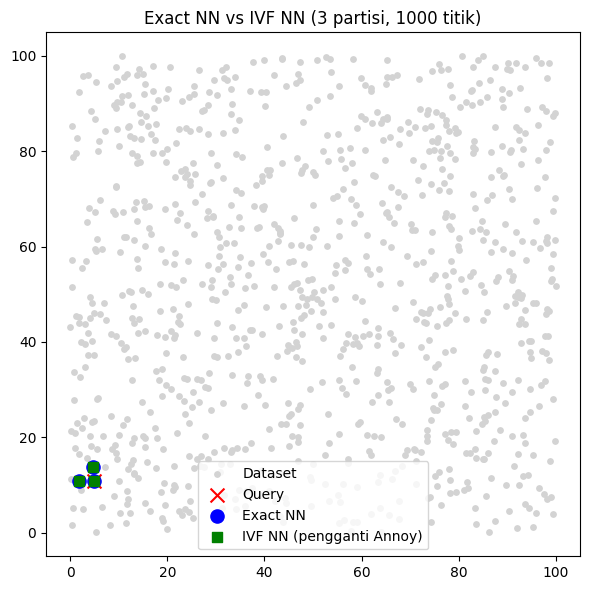

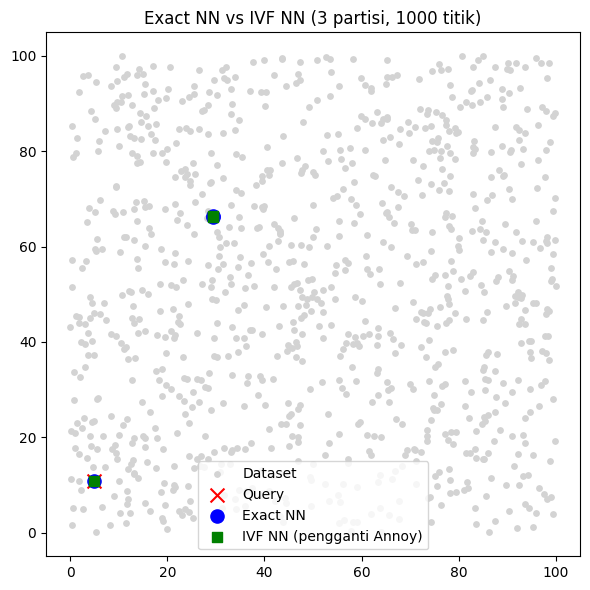

In [6]:
def recall(pred, gt):
    return float(np.mean([len(set(p) & set(g)) / len(g) for p, g in zip(pred, gt)]))


rows = []
for angular, metric in [(False, "Euclidean"), (True, "Angular")]:
    for n, trees in [(1000, 3), (1000, 8), (100_000, 3)]:
        rng = np.random.default_rng(42)
        X = rng.random((n, 2)) * 100
        Q = X[rng.integers(0, n, 50)]
        idx_e, t_e = exact_topk(X, Q, K, angular)
        idx_a, t_a, build = ivf_topk(X, Q, K, angular, nlist=trees)
        rec = recall(idx_a, idx_e)
        rows.append([metric, trees, n, t_e, build, t_a, round(t_e / t_a, 2), round(rec, 3)])
        print(f"{metric:9s} tree={trees} N={n:6d} | ENN {idx_e[0]} | ANN {idx_a[0]} "
              f"| exact {t_e:.3f} ms ANN {t_a:.3f} ms build {build:.1f} ms | recall@{K}={rec:.3f}")
        if n == 1000 and trees == 3:
            fig, ax = plt.subplots(figsize=(6, 6))
            ax.scatter(X[:, 0], X[:, 1], c="lightgray", s=15, label="Dataset")
            ax.scatter(*Q[0], c="red", marker="x", s=100, label="Query")
            ax.scatter(*X[idx_e[0]].T, c="blue", s=90, label="Exact NN")
            ax.scatter(*X[idx_a[0]].T, c="green", marker="s", s=45, label="IVF NN (pengganti Annoy)")
            ax.legend()
            ax.set_title(f"Exact NN vs IVF NN ({trees} partisi, {n} titik)")
            fig.tight_layout()
            fig.savefig(OUT / "p1_exact_vs_ann.png", dpi=120)

with open(OUT / "hasil_tabel.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["metrik", "tree/nlist", "jumlah_data", "exact_ms", "build_ms", "ann_ms", "speedup", "recall@3"])
    w.writerows(rows)

In [7]:
# ---- Simulasi rekomendasi track (20 fitur). Jobsheet memakai 50 juta baris;
# diperkecil ke 1 juta sesuai tabel & agar RAM aman (50jt x 20 float32 = 4 GB).
N, D, K5 = 1_000_000, 20, 5
rng = np.random.default_rng(7)
X = rng.random((N, D), dtype=np.float32)
Q = rng.random((20, D), dtype=np.float32)
t0 = time.perf_counter()
idx_e, t_e = exact_topk(X, Q, K5, False)
t_exact_total = time.perf_counter() - t0
idx_a, t_a, build_ms = ivf_topk(X, Q, K5, False, nlist=100, nprobe=10)
rec = recall(idx_a, idx_e)
print(f"\nSimulasi Spotify 1jt track x {D} fitur, k={K5}")
print(f"Exact: {t_exact_total:.2f} s total ({t_e:.3f} ms/query) hasil[0]={idx_e[0]}")
print(f"IVF  : build {build_ms/1000:.2f} s, {t_a:.3f} ms/query, hasil[0]={idx_a[0]}, recall={rec:.3f}")
print("\nJawaban: build index ANN tidak dihitung waktu query karena build adalah proses\n"
      "offline sekali jalan (preprocessing), sedangkan yang diukur adalah latency\n"
      "pencarian. Build justru lebih mahal dari exact search pada data kecil.")


Simulasi Spotify 1jt track x 20 fitur, k=5
Exact: 0.33 s total (15.892 ms/query) hasil[0]=[886500 924476 625732 654741   9149]
IVF  : build 0.64 s, 0.448 ms/query, hasil[0]=[886500 924476 625732 654741   9149], recall=0.920

Jawaban: build index ANN tidak dihitung waktu query karena build adalah proses
offline sekali jalan (preprocessing), sedangkan yang diukur adalah latency
pencarian. Build justru lebih mahal dari exact search pada data kecil.
